In [2]:

import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/yelp.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print("\nMissing values:\n", df.isnull().sum())


Dataset shape: (10000, 10)
Columns: ['business_id', 'date', 'review_id', 'stars', 'text', 'type', 'user_id', 'cool', 'useful', 'funny']


,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0



Missing values:
 business_id    0
date           0
review_id      0
stars          0
text           0
type           0
user_id        0
cool           0
useful         0
funny          0
dtype: int64


In [3]:

# Keep only clearly positive and negative reviews
df = df[df["stars"] != 3].copy()

# Create sentiment labels
df["sentiment"] = df["stars"].apply(
    lambda rating: "Positive" if rating >= 4 else "Negative"
)

# Remove empty reviews and duplicates
df = df.dropna(subset=["text", "sentiment"])
df = df.drop_duplicates(subset=["text"])

# Keep only the required columns
df = df[["text", "sentiment"]]

print("Dataset shape after cleaning:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nSample reviews:")
display(df.head())


Dataset shape after cleaning: (8537, 2)

Sentiment distribution:
sentiment
Positive    6862
Negative    1675
Name: count, dtype: int64

Sample reviews:


,text,sentiment
0,My wife took me here on my birthday for breakf...,Positive
1,I have no idea why some people give bad review...,Positive
2,love the gyro plate. Rice is so good and I als...,Positive
3,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",Positive
4,General Manager Scott Petello is a good egg!!!...,Positive


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

X = df["text"].astype(str)
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("model", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Positive"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Positive"
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label="Positive"
        )
    })

    print(f"\n{name}")
    print(classification_report(y_test, predictions))

results_df = pd.DataFrame(results)
display(results_df.round(4))



Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      0.02      0.04       335
    Positive       0.81      1.00      0.89      1373

    accuracy                           0.81      1708
   macro avg       0.90      0.51      0.47      1708
weighted avg       0.84      0.81      0.73      1708


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.72      0.81      0.76       335
    Positive       0.95      0.92      0.94      1373

    accuracy                           0.90      1708
   macro avg       0.84      0.87      0.85      1708
weighted avg       0.91      0.90      0.90      1708



,Model,Accuracy,Precision,Recall,F1-score
0,Multinomial Naive Bayes,0.8080,0.8072,1.0000,0.8933
1,Logistic Regression,0.9011,0.9526,0.9228,0.9375


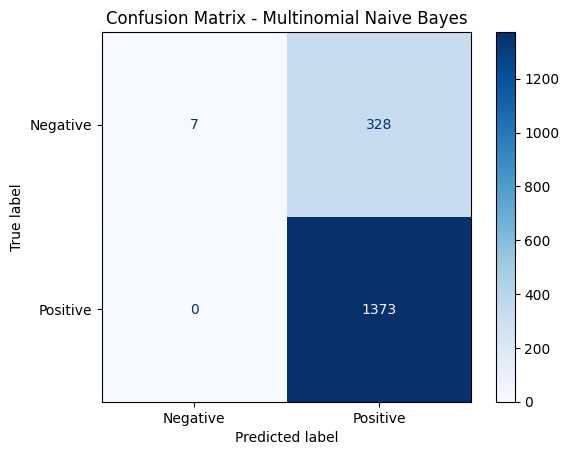

Multinomial Naive Bayes ROC-AUC: 0.9061


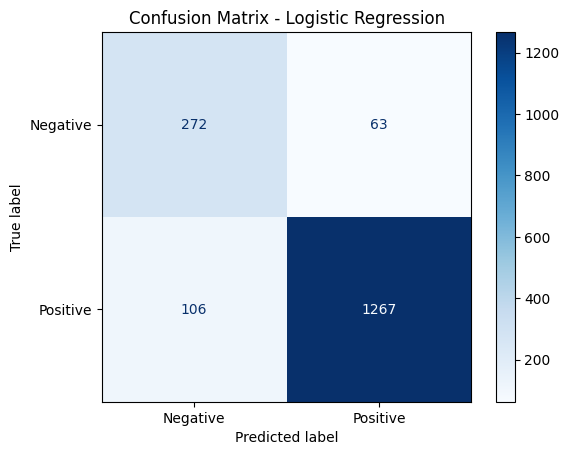

Logistic Regression ROC-AUC: 0.9545


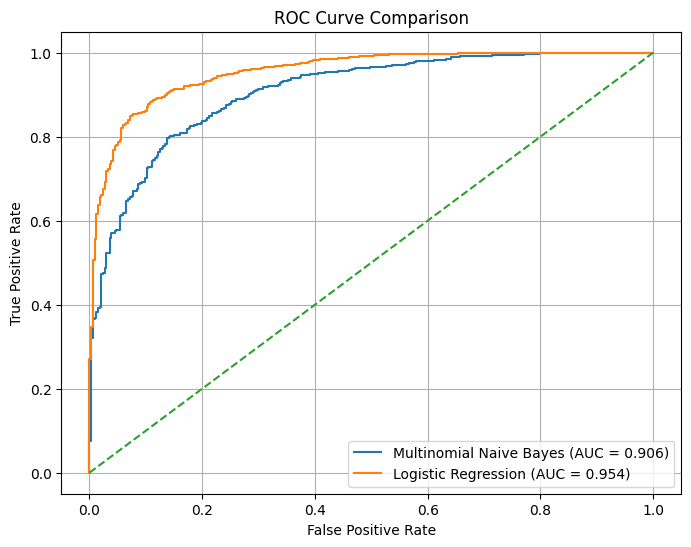

Top positive words:
['great' 'love' 'best' 'amazing' 'delicious' 'awesome' 'excellent'
 'favorite' 'fresh' 'perfect']

Top negative words:
['bland' 'horrible' 'bad' 'overpriced' 'rude' 'wasn' 'worst' 'ok' 'better'
 'awful']


In [5]:

from sklearn.metrics import (
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import numpy as np

# Confusion matrices for both models
for name, model in models.items():
    predictions = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=["Negative", "Positive"],
        cmap="Blues"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # ROC-AUC
    positive_index = list(model.classes_).index("Positive")
    probabilities = model.predict_proba(X_test)[:, positive_index]
    auc = roc_auc_score(
        (y_test == "Positive").astype(int),
        probabilities
    )
    print(f"{name} ROC-AUC: {auc:.4f}")

# ROC curve comparison
plt.figure(figsize=(8, 6))

for name, model in models.items():
    positive_index = list(model.classes_).index("Positive")
    probabilities = model.predict_proba(X_test)[:, positive_index]

    fpr, tpr, _ = roc_curve(
        (y_test == "Positive").astype(int),
        probabilities
    )
    auc = roc_auc_score(
        (y_test == "Positive").astype(int),
        probabilities
    )
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

# Top positive and negative words from Logistic Regression
lr = models["Logistic Regression"]
vectorizer = lr.named_steps["tfidf"]
classifier = lr.named_steps["model"]

feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = classifier.coef_[0]

top_positive = np.argsort(coefficients)[-10:]
top_negative = np.argsort(coefficients)[:10]

print("Top positive words:")
print(feature_names[top_positive][::-1])

print("\nTop negative words:")
print(feature_names[top_negative])


In [6]:

def predict_sentiment(review):
    model = models["Logistic Regression"]
    prediction = model.predict([review])[0]
    probabilities = model.predict_proba([review])[0]
    confidence = probabilities[list(model.classes_).index(prediction)]

    return {
        "Review": review,
        "Predicted Sentiment": prediction,
        "Confidence": round(float(confidence), 4)
    }

print(predict_sentiment("The food was amazing and the service was excellent!"))
print(predict_sentiment("The food was terrible and the service was very poor."))


{'Review': 'The food was amazing and the service was excellent!', 'Predicted Sentiment': 'Positive', 'Confidence': 0.8979}
{'Review': 'The food was terrible and the service was very poor.', 'Predicted Sentiment': 'Negative', 'Confidence': 0.8951}


In [7]:

# Add ROC-AUC to the model comparison table
for name, model in models.items():
    positive_index = list(model.classes_).index("Positive")
    probabilities = model.predict_proba(X_test)[:, positive_index]

    auc = roc_auc_score(
        (y_test == "Positive").astype(int),
        probabilities
    )

    results_df.loc[results_df["Model"] == name, "ROC-AUC"] = auc

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Multinomial Naive Bayes,0.8080,0.8072,1.0000,0.8933,0.9061
1,Logistic Regression,0.9011,0.9526,0.9228,0.9375,0.9545
